<a href="https://colab.research.google.com/github/shreeyeshapore/ML-Practicals/blob/main/Exp06_PCA_tSNE_Shreeyesha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Dimensionality Reduction using PCA and t-SNE

**Aim:** Apply PCA and t-SNE to reduce high-dimensional data to two dimensions, visualize the data, and compare classification accuracy before and after feature reduction.

**Libraries:** NumPy, Pandas, Matplotlib, Scikit-learn

Run the cells one by one.

## 1. Import libraries and load the dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

digits = load_digits()

# Use a subset of the dataset
X = digits.data[:1500]
y = digits.target[:1500]

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

Dataset shape: (1500, 64)
Number of classes: 10


## 2. Split the data and standardize features

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=10, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1050
Testing samples: 450


## 3. Accuracy using original features

In [3]:
knn = KNeighborsClassifier(n_neighbors=7)

knn.fit(X_train_scaled, y_train)

y_pred_original = knn.predict(X_test_scaled)

accuracy_original = accuracy_score(y_test, y_pred_original)

print("Accuracy with original features:", round(accuracy_original, 4))

Accuracy with original features: 0.9756


## 4. Apply PCA and compare accuracy

In [4]:
pca = PCA(n_components=3)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

knn_pca = KNeighborsClassifier(n_neighbors=7)
knn_pca.fit(X_train_pca, y_train)

y_pred_pca = knn_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Accuracy after PCA (3 features):", round(accuracy_pca, 4))
print("Variance retained after PCA:", round(pca.explained_variance_ratio_.sum(), 4))

Accuracy after PCA (3 features): 0.7711
Variance retained after PCA: 0.3044


## 5. Visualize PCA output

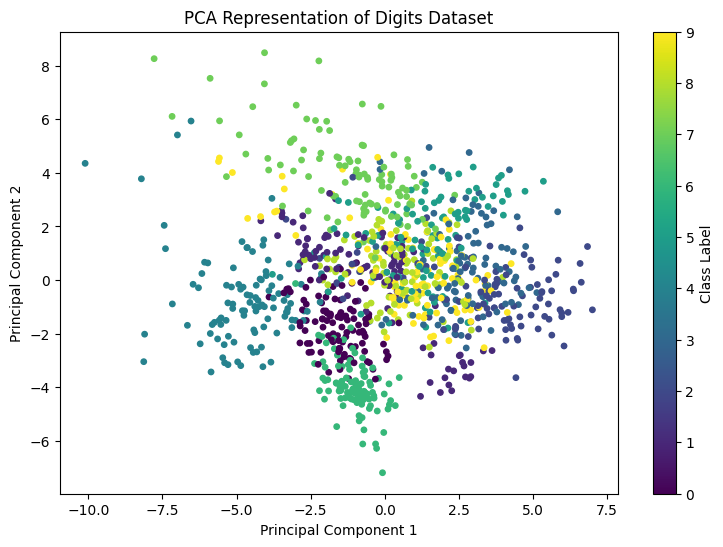

In [5]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    s=15
)

plt.title("PCA Representation of Digits Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Class Label")

plt.show()

## 6. Apply t-SNE for 2D visualization

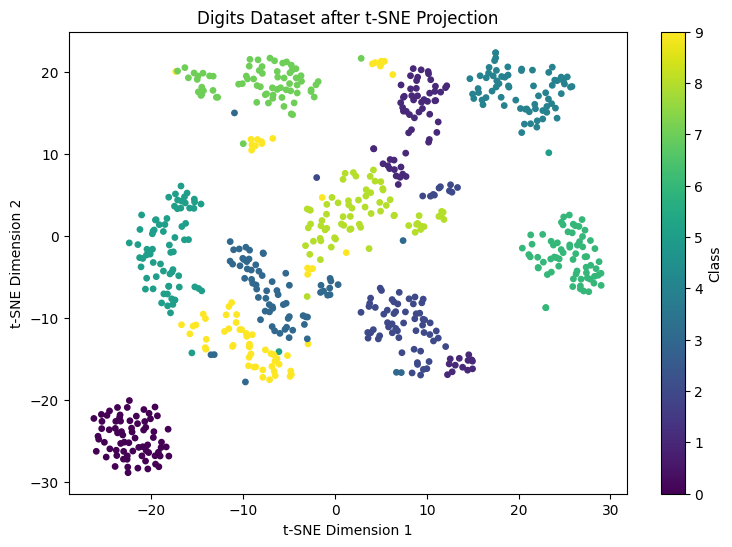

In [6]:
# t-SNE is used here for visualization. Fit it on a manageable sample.
sample_size = min(700, len(X))
X_sample = StandardScaler().fit_transform(X[:sample_size])
y_sample = y[:sample_size]

tsne = TSNE(n_components=2, random_state=10, perplexity=40,
            init="random", learning_rate="auto")
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=y_sample, cmap="viridis", s=15)
plt.title("Digits Dataset after t-SNE Projection")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.colorbar(scatter, label="Class")
plt.show()

## 7. Compare results

In [7]:
print("Original features (64):", round(accuracy_original, 4))
print("PCA features (3):       ", round(accuracy_pca, 4))

print("\nPCA may reduce accuracy when only three components are retained.")
print("t-SNE is mainly used for visualization and exploration.")
print("It is not generally used as a train/test transformation for prediction.")

Original features (64): 0.9756
PCA features (3):        0.7711

PCA may reduce accuracy when only three components are retained.
t-SNE is mainly used for visualization and exploration.
It is not generally used as a train/test transformation for prediction.


## Observations

1. The original digit dataset contains 64 input features.
2. PCA transforms the original features into principal components.
3. Three PCA components reduce the dimensionality of the data while retaining important information.
4. t-SNE helps reveal local groupings among digit classes.
5. Classification accuracy may decrease after reducing the features to only three dimensions.

## Result

PCA and t-SNE were applied to the Digits dataset. The data was visualized in reduced dimensions, and KNN accuracy using original features was compared with accuracy after PCA feature reduction.